# CAES Mini-Project: Variant 1b System Design and Simulation

Compressed Air Energy Storage (CAES) stores electricity during off-peak hours by compressing ambient air into a storage reservoir. During discharge, the compressed air is extracted, heated via a combustor, and expanded through a turbine to generate electricity. 

## Variant 1b Description

**Variant 1b** models a single-stage, non-adiabatic CAES plant with a constant-pressure reservoir:

* **Charge:** Ambient air is compressed in a single-stage compressor directly to the storage pressure $P_{\text{max}}$. The heat of compression is removed via a water cooler and rejected to ambient (no thermal storage), bringing the air towards ambient temperature before storage.

* **Discharge:** Air leaves the store at a constant inlet pressure of 16 bar (quasi-steady expansion). A fuel combustor heats the air from near ambient conditions up to the turbine inlet temperature ($550^\circ\text{C}$) before it expands across a single turbine stage to ambient pressure.

## System Specifications & Given Parameters

| Category | Parameter | Symbol | Value | Unit / Description |
|---|---|---|---|---|
| **Fluid Properties** | Working fluid | — | Air | Real-gas properties via CoolProp (`"Air"`) |
| **Ambient Conditions** | Ambient temperature | $T_0$ | 15 (288.15) | °C (K) |
| | Ambient pressure | $P_0$ | 1.013 | bar (compressor inlet / turbine exhaust) |
| **Storage Conditions** | Storage / max pressure | $P_{\text{max}}$ | 16 | bar (held constant during operation) |
| | Reservoir thermal state | $T_{\text{res}}$ | 15 (288.15) | °C (assumed returns and remains at $T_0$) |
| **Operating Targets** | Discharge shaft power | $P_{\text{shaft}}$ | 1 | MW |
| | Discharge duration | $\Delta t_{\text{dis}}$ | 4 | h (delivers 4 MWh per cycle) |
| | Charge duration | $\Delta t_{\text{ch}}$ | 4 | h (governs charge mass flow rate) |
| **Component Efficiencies** | Compressor isentropic efficiency | $\eta_{\text{is,c}}$ | 0.85 | Single stage |
| | Turbine isentropic efficiency | $\eta_{\text{is,t}}$ | 0.88 | Single stage |
| | Mechanical / generator efficiency | $\eta_{\text{mech}}$ | 0.98 | Shaft transmission / generator conversion |
| **Thermal Parameters** | Cooler pinch | $\Delta T_{\text{pinch}}$ | 10 | K (air cooled towards $T_0 + 10\text{ K}$) |
| | Turbine inlet temperature | TIT | 550 (823.15) | °C (K), achieved via direct heat addition |
| | Reference fuel-to-electricity efficiency | $\eta_f$ | 0.40 | Metric weighting factor for fuel input |

## Design and Simulation Tasks

The project workflow for Variant 1b consists of two phases:

1. **Design Mode:**
   * Size the single-stage compressor and turbine for the specified 1 MW / 4 h delivery target.
   * Size the water cooler heat-exchanger area ($A$) based on the aftercooling duty and 10 K pinch.
   * Size the required constant-pressure storage volume ($V$) needed to store the total cycle air mass.

2. **Simulation Mode:**
   * Simulate a full charge and discharge cycle under quasi-steady constant-pressure operation.
   * Compute the overall round-trip efficiency ($\eta$), where fuel is converted to its electrical equivalent:
     $$\eta = \frac{W_{\text{turbine}}}{W_{\text{compressor}} + \eta_f \cdot Q_{\text{combustion}}}, \qquad \eta_f = 0.40$$
   * Evaluate the energy balance, the electrical vs. fuel input split ($W_{\text{compressor}}$ vs. $Q_{\text{combustion}}$), and the peak compressor discharge temperature.
   * Provide at least one quantified performance improvement proposal and benchmark the storage volume and efficiency against the sliding-pressure variant (1a).

Here are some sources i used to return to later (soso)

Return to Gas Turbines EENG4 S8 for compressor eq and details (soso)

Paper on which sile will the pinch temp be occuring based on the Cc and Ch (LMTD) method. https://sci-hub.fr/10.1016/B978-008042839-0/50008-2 (soso)

Also return to EENG3 S6 Lec 4 for counter flow details and eq (soso)

The following section defines the imports used in the code

In [ ]:
# --- imports ---
from pathlib import Path
import sys

import numpy as np
from CoolProp.CoolProp import PropsSI

import caldis
from caldis.core.system import System
from caldis.components import FluidBoundary, Compressor, SizingHX, CombustionChamber, Turbine
from caldis.components.vessels.tank import TankConstP

from caldis.fluids import CoolPropBackend

from caldis.solvers import dynamic, solve, simulate

print("Caldis OK", caldis.__version__)


## Parameters

In [42]:
# ==============================================================================
# 1. Given in the Document (Specification)
# ==============================================================================

# Fluid property backends
be_air = CoolPropBackend("Air")
be_fuel = CoolPropBackend("Methane")
be_water = CoolPropBackend("Water")


# Reference ambient conditions
T0 = 15.0 + 273.15           # [K] Ambient temperature
Tpinch = 10                  # [K] Ambient temperature
P0 = 1.013e5                 # [Pa] Ambient pressure

# Operational targets
W_target = 1.0e6             # [W] Turbine net shaft power (1 MW target)
t_discharge = 4.0 * 3600.0   # [s] Discharge duration (4 h -> 4 MWh)
t_charge = 4.0 * 3600.0      # [s] Charge duration (4 h)

# Cycle and storage operating limits
Pmax = 16.0e5                # [Pa] Storage pressure (constant pressure)
Ttit = 550.0 + 273.15        # [K] Turbine inlet temperature
T_pinch = 10.0               # [K] Cooler pinch temperature difference

# Component efficiencies
Eta_ISC = 0.85               # Compressor isentropic efficiency
Eta_IST = 0.88               # Turbine isentropic efficiency
Eta_Mech = 0.98              # Mechanical / generator efficiency
Eta_Fuel = 0.40              # Fuel-to-electricity reference efficiency

In [43]:
# ==============================================================================
# Derived Thermo dynamic properties
# ==============================================================================

# Tank Properties
h_tank_charge = PropsSI("H", "T", T0 + T_pinch, "P", Pmax, "Air")           # [J/kg] Stored air enthalpy
h_tank_discharge = PropsSI("H", "T", T0, "P", Pmax, "Air")        # [J/kg] Stored air enthalpy

rho_tank_Air_discharge = PropsSI("D", "T", T0, "P", Pmax, "Air")  # [kg/m³] Stored air density

# Turbine Properties
P_turb_in = Pmax * (1.0 - 0.04)                                   # [Pa] 15.36 bar                                           
h_turb_in = PropsSI("H", "T", Ttit, "P", P_turb_in , "Air")       # [J/kg]
s_turb_in = PropsSI("S", "T", Ttit, "P", P_turb_in, "Air")        # [J/(kg·K)]
h_turb_out_s = PropsSI("H", "P", P0, "S", s_turb_in, "Air")       # [J/kg]

In [44]:
# ==============================================================================
# Sizing Parameters for Heat Exchanger (Aftercooler)
# ==============================================================================

# Cooling water inlet and operating states
T_water_in = T0              # [K] Cooling water inlet temperature
P_water_in = P0              # [Pa] Cooling water inlet pressure
T_water_out_guess = 100.0 + 273.15  # [K] Water outlet temperature initial guess

# Convection film heat transfer coefficients
h_film_air = 100.0           # [W/(m²·K)] Air-side film coefficient
h_film_water = 3000.0        # [W/(m²·K)] Water-side film coefficient

# Geometric configuration
Ratio_Area_cold_to_hot = 0.5 # Cold-side to hot-side heat transfer area ratio

In [45]:
# ==============================================================================
# Flowrate Calculations
# ==============================================================================

# Net specific work delivered at shaft
w_sp = Eta_Mech * Eta_IST * (h_turb_in - h_turb_out_s)          # [J/kg]

# Required mass flow rates during charge and discharge
Mdot_discharge = W_target / w_sp                                # [kg/s] Air discharge flow rate
Mass_total = Mdot_discharge * t_discharge                       # [kg] Total air mass required
Mdot_charge = Mass_total / t_charge    

# Guess Estimation of fuel flowrate
Mdot_fuel = 0.286


In [46]:
# ==============================================================================
# Sizing for Tank Volume (Cylinder — Stainless Steel 304)
# ==============================================================================

# Required reservoir volume 
V_tank_initial = (Mass_total / rho_tank_Air_discharge)            # [m³] Initial storage volume

# Material properties: Stainless Steel 304
Density_Steel_304 = 7955.0   # [kg/m³]
Cp_Tank = 500.0              # [J/(kg·K)]
k_steel = 16.0               # [W/(m·K)] Thermal conductivity

# Cylinder vessel dimensions
Diameter_Tank_out = 8.0      # [m] Outer diameter
Thickness_wall = 0.12        # [m] Wall thickness

r_out = Diameter_Tank_out / 2.0             # [m] Outer radius
r_in = r_out - Thickness_wall               # [m] Inner radius
r_mid = (r_out + r_in) / 2.0                # [m] Mid-wall radius

# Cylinder geometric sizing
Area_Tank_in_cs = np.pi * (r_in ** 2)                  # [m²] Inner cross-sectional area
Area_Tank_Shell_cs = np.pi * (r_out ** 2 - r_in ** 2)  # [m²] Annular shell cross section
Length_Tank = V_tank_initial / Area_Tank_in_cs         # [m] Cylinder length

Area_Tank_in_surf = 2.0 * np.pi * r_in * Length_Tank   # [m²] Internal convective surface area
Volume_Tank_Shell = Area_Tank_Shell_cs * Length_Tank  # [m³] Metal shell volume
Mass_Tank = Density_Steel_304 * Volume_Tank_Shell      # [kg] Total vessel shell mass

# Wall thermal capacitance
Cwall = Mass_Tank * Cp_Tank                            # [J/K] Wall heat capacity

# Thermal conductance between wall and fluid
h_in = 50.0                                            # [W/(m²·K)] Internal convection coefficient
R_conv_in = 1.0 / (h_in * Area_Tank_in_surf)           # [K/W] Convective resistance
R_wall_inner = np.log(r_mid / r_in) / (2.0 * np.pi * k_steel * Length_Tank)  # [K/W] Conduction
UA_wall = 1.0 / (R_conv_in + R_wall_inner)             # [W/K] Wall-to-fluid thermal conductance

# Heat replenishment rate to offset constant-pressure volume contraction cooling
#Q_boundary_work = Mdot_discharge * (Pmax / rho_tank)   # [W] Expansion boundary heat rate


## Charge Phase
| Step | Component | Flow / Working Fluid | Energy / Secondary Streams |
|:---:|:---|:---|:---|
| **1** | **Ambient Intake** | Air at ambient ($T_0 = 15^\circ\text{C},\; P_0 = 1.013\text{ bar}$) | — |
| | $\Downarrow$ | *Suction line* | |
| **2** | **Compressor** | Single-stage compression $\rightarrow P_{\text{max}} = 16\text{ bar}$ | $\longleftarrow$ **Compressor work (elec. in)** |
| | $\Downarrow$ | *Hot compressed air* | |
| **3** | **Cooler (water)** | Cooled to $T_0 + 10\text{ K} = 25^\circ\text{C}$ | $\longrightarrow$ **Rejected heat (not recovered)** |
| | $\Downarrow$ | *Cooled air at $16\text{ bar}$* | |

In [47]:
# --- Component setup ---
Source_Charge     = FluidBoundary(name="Source", p=P0, T=T0, h=None, mdot=-Mdot_charge, backend=be_air)
Comp_Charge       = Compressor(name="Comp", backend=be_air, eta_is=Eta_ISC)

# Since Ch<Cc in a counter flow heat exchanger, the pinch point is on the cold side.
# As the outlet of the heat exchanger was set to be T0 + 10, 
# Then the inlet of the water on the cold side would be T0 + 10 - Tpinch= T0
# Pressure is assumed to be atm as it does not affect the heat transfer
Water_Cold_Charge = FluidBoundary(name="Water_Cold", p=P0, T=T0, h=None, mdot=-Mdot_charge, backend=be_water)
Water_Hot_Charge  = FluidBoundary(name="Water_Hot",  p=None, T=None, h=None, mdot=None, backend=be_water)

# The area ratio of the heat exchanger is set to 0.5, 
# meaning that the area of the cold side is half of the area of the hot side. 
# This is a reasonable assumption for a counter flow heat exchanger.
# hfilm defined in A3
Hex_Charge = SizingHX(name="Hex", backend_hot=be_air, backend_cold=be_water, h_hot=h_film_air, h_cold=h_film_water, area_ratio_cold_to_hot=Ratio_Area_cold_to_hot)
Tank_Charge = TankConstP(name="Tank", backend=be_air, p=Pmax, h_init=h_tank_discharge, V_init=20, C_wall=Cwall, T_wall_init=T0, UA_wall=UA_wall, Q_heater=0)

Closed_Outlet = FluidBoundary(name="Closed_Out", mdot=0.0, backend=be_air)  # No discharge during charge

In [48]:
# ==============================================================================
# Charge Subsystem Component Definitions
# ==============================================================================

# Cooling water mass flow rate (keeps water temperature safe at ~55 °C)
Mdot_water = 6.0  # [kg/s]

# 1. Steady-state Charge Design Components (Compressor & Cooler Sizing)
Source_Charge = FluidBoundary(name="Source_Charge", p=P0, T=T0, mdot=-Mdot_charge, backend=be_air)

Comp_Charge = Compressor(name="Comp_Charge", backend=be_air, eta_is=Eta_ISC)

Water_Cold_Charge = FluidBoundary(name="Water_Cold", p=P0, T=T0, mdot=-Mdot_water, backend=be_water)

Water_Hot_Charge = FluidBoundary(name="Water_Hot", backend=be_water)

Hex_Charge = SizingHX(
    name="Hex_Charge",
    backend_hot=be_air,
    backend_cold=be_water,
    h_hot=h_film_air,
    h_cold=h_film_water,
    area_ratio_cold_to_hot=Ratio_Area_cold_to_hot
)

Cooled_Air_Sink = FluidBoundary(name="Cooled_Sink", p=Pmax, T=T0 + T_pinch, backend=be_air)

# 2. Dynamic Tank Charge Components (Filling the Tank over 4 Hours)
Air_from_Cooler = FluidBoundary(name="Air_Inflow", T=T0 + T_pinch, mdot=-Mdot_charge, backend=be_air)
Tank_Charge = TankConstP(
    name="Tank_Charge",
    backend=be_air,
    p=Pmax,
    h_init=h_tank_charge,
    V_init=0,              # [m³] Minimum reserve volume at start of charge
    C_wall=Cwall,
    T_wall_init=T0,
    UA_wall=UA_wall,
    Q_heater=0.0
)
Closed_Outlet_Charge = FluidBoundary(name="Closed_Out", mdot=0.0, backend=be_air)

In [49]:
# ==============================================================================
# Part A: Steady-State Charge Design (Compressor & Cooler Sizing)
# ==============================================================================
sys_charge_design = System("Charge_Design")
sys_charge_design.add(Source_Charge, Comp_Charge, Hex_Charge, Water_Cold_Charge, Water_Hot_Charge, Cooled_Air_Sink)

# Connections
sys_charge_design.connect(Source_Charge.port,     Comp_Charge.inl)
sys_charge_design.connect(Comp_Charge.out,        Hex_Charge.hot_in)
sys_charge_design.connect(Hex_Charge.hot_out,     Cooled_Air_Sink.port)
sys_charge_design.connect(Water_Cold_Charge.port, Hex_Charge.cold_in)
sys_charge_design.connect(Hex_Charge.cold_out,    Water_Hot_Charge.port)

# Starting points
sys_charge_design.set_start_port(Comp_Charge.inl,     p=P0,   T=T0,                 mdot= Mdot_charge)
sys_charge_design.set_start_port(Comp_Charge.out,     p=Pmax, T=410.0 + 273.15,     mdot=-Mdot_charge)
sys_charge_design.set_start_port(Hex_Charge.hot_in,   p=Pmax, T=410.0 + 273.15,     mdot= Mdot_charge)
sys_charge_design.set_start_port(Hex_Charge.hot_out,  p=Pmax, T=T0 + T_pinch,       mdot=-Mdot_charge)
sys_charge_design.set_start_port(Hex_Charge.cold_in,  p=P0,   T=T0,                 mdot= Mdot_water)
sys_charge_design.set_start_port(Hex_Charge.cold_out, p=P0,   T=T0 + 40.0,          mdot=-Mdot_water)
sys_charge_design.init_starts()

# Solve steady-state sizing
sol_charge = solve(sys_charge_design)

Wdot_comp = Comp_Charge.inl.mdot * (Comp_Charge.out.h - Comp_Charge.inl.h)  # [W]
W_comp_total = Wdot_comp * t_charge                                        # [J]

print("=== Charge Design (Sizing Results) ===")
print(f"Compressor Electrical Power: {Wdot_comp / 1e6:.4f} MW")
print(f"Compressor Electric Energy:  {W_comp_total / (3600.0 * 1e6):.4f} MWh")
print(f"Compressor Outlet Temp:      {Comp_Charge.out.T - 273.15:.2f} °C")
print(f"Cooler Air Outlet Temp:      {Hex_Charge.hot_out.T - 273.15:.2f} °C")
print(f"Cooler Water Outlet Temp:    {Hex_Charge.cold_out.T - 273.15:.2f} °C")
print(f"Cooler Area (A_hot):         {Hex_Charge.A_hot:.2f} m²")
print(f"Cooler Area (A_cold):        {Hex_Charge.params['area_ratio_cold_to_hot'] * Hex_Charge.A_hot:.2f} m²")
print(f"Cooler Total Area:           {Hex_Charge.A_hot * (1.0 + Hex_Charge.params['area_ratio_cold_to_hot']):.2f} m²")
print(f"Cooler Conductance (UA):     {Hex_Charge.UA:.2f} W/K")

# ==============================================================================
# Part B: Dynamic Tank Filling Simulation (4 Hours)
# ==============================================================================
sys_charge_dyn = System("Charge_Dynamic")
sys_charge_dyn.add(Air_from_Cooler, Tank_Charge, Closed_Outlet_Charge)

sys_charge_dyn.connect(Air_from_Cooler.port, Tank_Charge.inl)
sys_charge_dyn.connect(Tank_Charge.out,      Closed_Outlet_Charge.port)

sys_charge_dyn.set_start_port(Air_from_Cooler.port,      p=Pmax, T=T0 + T_pinch, mdot=-Mdot_charge)
sys_charge_dyn.set_start_port(Tank_Charge.inl,          p=Pmax, T=T0 + T_pinch, mdot= Mdot_charge)
sys_charge_dyn.set_start_port(Tank_Charge.out,          p=Pmax, T=T0 + T_pinch, mdot= 0.0)
sys_charge_dyn.set_start_port(Closed_Outlet_Charge.port, p=Pmax, T=T0 + T_pinch, mdot= 0.0)
sys_charge_dyn.init_starts()

results_charge = simulate(sys_charge_dyn, t_end=t_charge, dt=240, init="consistent", progress=True)

df_charge = results_charge.to_dataframe()
print("\n=== Charge Dynamic Simulation Finished ===")
V_charged = df_charge["Tank_Charge.V"].iloc[-1]  # Expands to ~1890 - 1970 m³

  

=== Charge Design (Sizing Results) ===
Compressor Electrical Power: 1.0350 MW
Compressor Electric Energy:  4.1401 MWh
Compressor Outlet Temp:      410.00 °C
Cooler Air Outlet Temp:      25.00 °C
Cooler Water Outlet Temp:    99.85 °C
Cooler Area (A_hot):         1.00 m²
Cooler Area (A_cold):        0.50 m²
Cooler Total Area:           1.50 m²
Cooler Conductance (UA):     1000.00 W/K
✓ DOF: square (17 unknowns)
✓ start point: evaluable
  simulate  [  60/60]  t=14400.0s  |F|=1.7e-10

=== Charge Dynamic Simulation Finished ===


In [50]:
Hex_Charge.describe()

=== SizingHX('Hex_Charge') ===
  variables:
    UA               = 1000
    A_hot            = 1
  ports (p [bar], mdot [kg/s], T [°C]):
    hot_in     p=16.000  mdot=+2.54  h=821.8kJ/kg  T=410.00
    hot_out    p=16.000  mdot=-2.54  h=421.0kJ/kg  T=25.00
    cold_in    p=1.013  mdot=+6  h=63.1kJ/kg  T=15.00
    cold_out   p=1.013  mdot=-6  h=418.5kJ/kg  T=99.85


{'variables': {'UA': [1000.0], 'A_hot': [1.0]},
 'ports': {'hot_in': {'p': 1600000.0,
   'mdot': 2.5403929977966597,
   'h': 821799.6783034737},
  'hot_out': {'p': 1600000.0,
   'mdot': -2.5403929977966597,
   'h': 421048.5357981671},
  'cold_in': {'p': 101300.0, 'mdot': 6.0, 'h': 63076.80686917259},
  'cold_out': {'p': 101300.0, 'mdot': -6.0, 'h': 418533.73616995814}},
 'outputs': {}}

## Discharge Phase
| Step | Reservoir | Flow / Working Fluid | Energy / Secondary Streams |
|:---:|:---|:---|:---|
| | $\Downarrow$ | *Extraction line (constant inlet pressure $16\text{ bar}$)* | |
| **1** | **Combustor** | Direct heat addition up to $\text{TIT} = 550^\circ\text{C}$ | $\longleftarrow$ **Fuel heat input ($Q$)** |
| | $\Downarrow$ | *High-pressure hot gas at $16\text{ bar},\; 550^\circ\text{C}$* | |
| **2** | **Turbine** | Single-stage expansion down to ambient ($P_0$) | $\longrightarrow$ **Turbine work (elec. out: 1 MW)** |
| | $\Downarrow$ | *Exhaust gas* | |
| **3** | **Exhaust** | Discharged to ambient atmosphere ($P_0$) | — |

In [51]:
# --- Discharge Cycle ---
Source = FluidBoundary(name="Source", T=T0, mdot=0, backend=be_air)
Tank = TankConstP(name="Tank", backend=be_air, p=Pmax, h_init=h_tank_discharge, V_init=V_charged, C_wall=Cwall, T_wall_init=T0, UA_wall=UA_wall, Q_heater=0)
Source_Discharge = Source
Tank_Discharge = Tank
Comb = CombustionChamber(name="Comb", backend_air=be_air, backend_fuel=be_fuel, LHV=50e6, eta_comb=1.0, dp_rel=0.04)
Fuel_in = FluidBoundary(name="Fuel_in", p=P0, T=T0, backend=be_fuel)
Turbine = Turbine(name="Turbine", backend=be_air, eta_is=Eta_IST, eta_mech=Eta_Mech)
Exhaust = FluidBoundary(name="Exhaust", p=P0, backend=be_air)


In [52]:
# --- System wiring ---
sys_ = System("Discharge_Cycle")
sys_.add(Source, Tank, Turbine, Comb, Fuel_in, Exhaust)

sys_.connect(Source.port,  Tank.inl)
sys_.connect(Tank.out,     Comb.air_in)
sys_.connect(Fuel_in.port, Comb.fuel_in)
sys_.connect(Comb.gas_out, Turbine.inl)
sys_.connect(Turbine.out,  Exhaust.port)

# --- Constraints ---
# 1. Combustor reaches TIT = 550°C
sys_.add_constraint(lambda: be_air.T(Comb.gas_out.p, Comb.gas_out.h) - Ttit, "TIT_550C")

# 2. Turbine delivers 1 MW net shaft power
sys_.add_constraint(lambda: Eta_Mech * Turbine.inl.mdot * (Turbine.inl.h - Turbine.out.h) - W_target, "Wdot_1MW")

# --- Start Hints ---
sys_.set_start_port(Tank.out,      p=Pmax,           T=Tank.out.T,    mdot= - Mdot_discharge)
sys_.set_start_port(Fuel_in.port,  p=P0,             T=T0,            mdot= - Mdot_fuel)
sys_.set_start_port(Comb.air_in,   p=Tank.out.p,     T=Tank.out.T,    mdot=   Mdot_discharge)
sys_.set_start_port(Comb.gas_out,  p=Comb.gas_out.p, T=Ttit,          mdot= - Mdot_discharge)
sys_.set_start_port(Turbine.inl,   p=Comb.gas_out.p, T=Ttit,          mdot=   Mdot_discharge)
sys_.set_start_port(Turbine.out,   p=P0,             T=Turbine.out.T, mdot= - Mdot_discharge)
sys_.set_start_port(Exhaust.port,  p=P0,             T=Turbine.out.T, mdot=   Mdot_discharge)
sys_.init_starts()

# --- Run 4-Hour Dynamic Simulation ---
results = simulate(sys_, t_end=t_discharge, dt=240, init="consistent", progress=True)

# --- Inspect Results ---
df = results.to_dataframe()
print("\n=== Discharge Simulation Finished Successfully ===")
print(f"Air mass flow rate:       {abs(df['Tank.fluid.out.mdot'].iloc[0]):.4f} kg/s")
print(f"Fuel mass flow rate:      {abs(df['Fuel_in.port.mdot'].iloc[0]):.5f} kg/s")
print(f"Turbine power delivered:  {df['Turbine.Wdot'].iloc[0]/1e6:.4f} MW")
print(f"Starting Tank Volume:     {df['Tank.V'].iloc[0]:.1f} m³")
print(f"Final Tank Volume (4h):   {df['Tank.V'].iloc[-1]:.1f} m³")

✓ DOF: square (35 unknowns)
✓ start point: evaluable
⚠ 1 start-sanity warning(s):
   - Turbine: p_out (1.01 bar) must be < p_in (1.00 bar) for expansion
  (non-blocking.)


  simulate  [  60/60]  t=14400.0s  |F|=2.4e-09

=== Discharge Simulation Finished Successfully ===
Air mass flow rate:       2.5117 kg/s
Fuel mass flow rate:      0.02864 kg/s
Turbine power delivered:  1.0000 MW
Starting Tank Volume:     1958.2 m³
Final Tank Volume (4h):   96.2 m³


=== Variant 1B Answers ===
Scope: single-stage, no thermal storage, constant-pressure reservoir (16 bar).
Design mode
  Compressor electrical power:     1.035 MW
  Compressor electrical energy:    4.140 MWh per 4 h charge
  Peak compressor outlet temp:     410.0 °C
  Cooler air outlet temp:          25.0 °C
  Cooler area, hot + cold sides:   1.00 + 0.50 = 1.50 m²
  Cooler conductance (UA):         1000.0 W/K
  Cooling duty rejected:           1.018 MW (14.660 GJ per charge)
  Static tank-volume estimate:      1,879.7 m³
  Dynamic charged tank volume:      1,958.2 m³
Simulation mode
  Discharge duration:              4.00 h
  Mean turbine power delivered:    1.000 MW
  Turbine energy delivered:        4.000 MWh
  Combustion heat supplied:        20.895 GJ (5.804 MWh thermal)
  Fuel electrical-equivalent:      2.322 MWh (eta_f = 0.40)
  Round-trip efficiency:           61.90% = W_turbine / (W_compressor + eta_f * Q_combustion)
  Weighted input split:            compressor 64.1%, fuel 35.

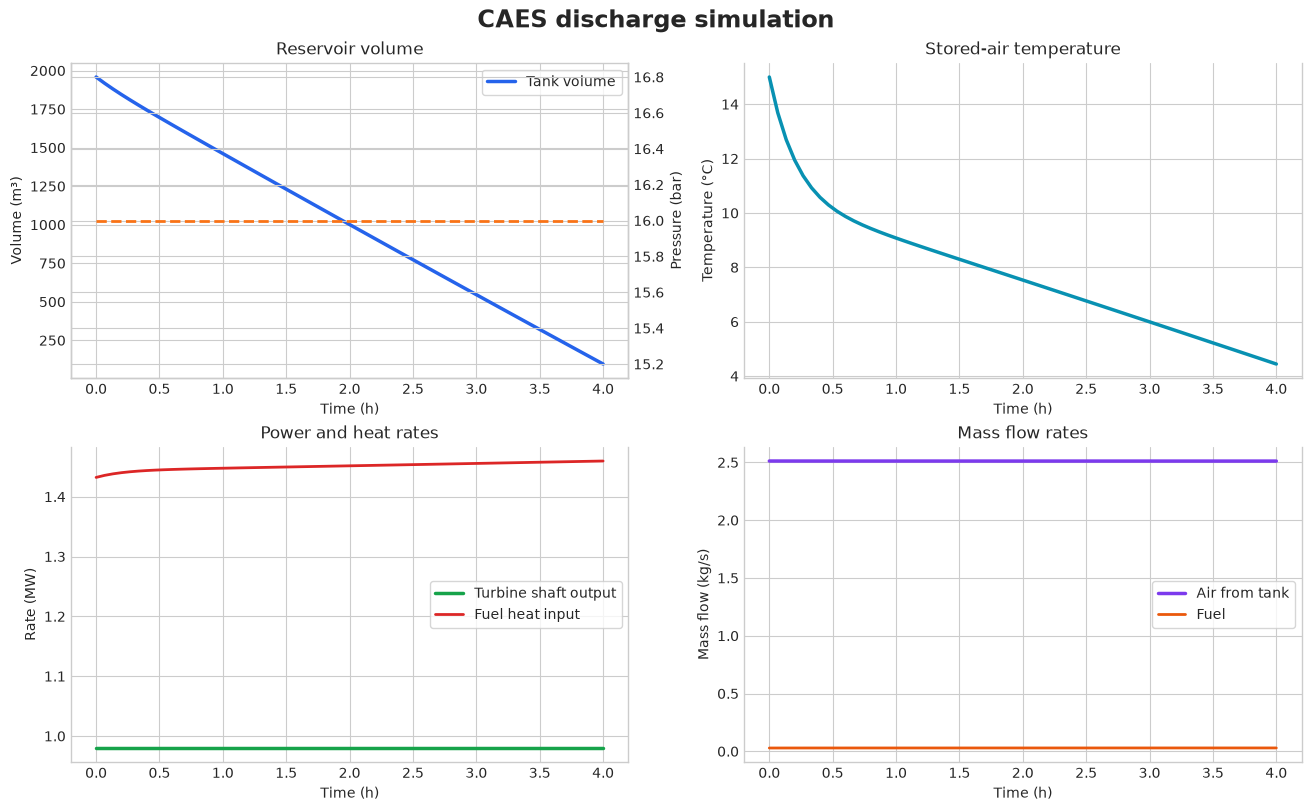

In [57]:
import matplotlib.pyplot as plt

# Extract simulation data
time_s = df["time"].to_numpy()
time_h = time_s / 3600

air_flow = df["Tank.fluid.out.mdot"].abs().to_numpy()
fuel_flow = df["Fuel_in.port.mdot"].abs().to_numpy()
# Turbine.Wdot already includes Eta_Mech in the Turbine component.
shaft_power = df["Turbine.Wdot"].to_numpy()
fuel_heat_rate = df["Comb.Qdot_fuel"].to_numpy()

# Integrate rates over the simulated discharge
turbine_energy_J = np.trapezoid(shaft_power, time_s)
fuel_energy_J = np.trapezoid(fuel_heat_rate, time_s)
air_mass_kg = np.trapezoid(air_flow, time_s)
fuel_mass_kg = np.trapezoid(fuel_flow, time_s)

volume = df["Tank.V"].to_numpy()
tank_temp_C = df["Tank.fluid.T"].to_numpy() - 273.15
tank_pressure_bar = df["Tank.fluid.out.p"].to_numpy() / 1e5
fuel_electric_equivalent_J = Eta_Fuel * fuel_energy_J
weighted_input_J = W_comp_total + fuel_electric_equivalent_J
round_trip_efficiency = turbine_energy_J / weighted_input_J
charge_heat_rejected_W = Mdot_charge * (Comp_Charge.out.h - Hex_Charge.hot_out.h)

print("=== Variant 1B Answers ===")
print("Scope: single-stage, no thermal storage, constant-pressure reservoir (16 bar).")
print("Design mode")
print(f"  Compressor electrical power:     {Wdot_comp / 1e6:.3f} MW")
print(f"  Compressor electrical energy:    {W_comp_total / 3.6e9:.3f} MWh per 4 h charge")
print(f"  Peak compressor outlet temp:     {Comp_Charge.out.T - 273.15:.1f} °C")
print(f"  Cooler air outlet temp:          {Hex_Charge.hot_out.T - 273.15:.1f} °C")
print(f"  Cooler area, hot + cold sides:   {Hex_Charge.A_hot:.2f} + {Hex_Charge.params['area_ratio_cold_to_hot'] * Hex_Charge.A_hot:.2f} = {Hex_Charge.A_hot * (1.0 + Hex_Charge.params['area_ratio_cold_to_hot']):.2f} m²")
print(f"  Cooler conductance (UA):         {Hex_Charge.UA:.1f} W/K")
print(f"  Cooling duty rejected:           {charge_heat_rejected_W / 1e6:.3f} MW ({charge_heat_rejected_W * t_charge / 1e9:.3f} GJ per charge)")
print(f"  Static tank-volume estimate:      {V_tank_initial:,.1f} m³")
print(f"  Dynamic charged tank volume:      {V_charged:,.1f} m³")
print("Simulation mode")
print(f"  Discharge duration:              {time_h[-1]:.2f} h")
print(f"  Mean turbine power delivered:    {turbine_energy_J / (time_s[-1] - time_s[0]) / 1e6:.3f} MW")
print(f"  Turbine energy delivered:        {turbine_energy_J / 3.6e9:.3f} MWh")
print(f"  Combustion heat supplied:        {fuel_energy_J / 1e9:.3f} GJ ({fuel_energy_J / 3.6e9:.3f} MWh thermal)")
print(f"  Fuel electrical-equivalent:      {fuel_electric_equivalent_J / 3.6e9:.3f} MWh (eta_f = {Eta_Fuel:.2f})")
print(f"  Round-trip efficiency:           {100 * round_trip_efficiency:.2f}% = W_turbine / (W_compressor + eta_f * Q_combustion)")
print(f"  Weighted input split:            compressor {100 * W_comp_total / weighted_input_J:.1f}%, fuel {100 * fuel_electric_equivalent_J / weighted_input_J:.1f}%")
print(f"  Air discharged / fuel consumed:  {air_mass_kg:,.0f} kg / {fuel_mass_kg:,.1f} kg")
print(f"  Tank volume, start to finish:    {volume[0]:,.1f} -> {volume[-1]:,.1f} m³")
print(f"  Tank pressure range:             {tank_pressure_bar.min():.2f}-{tank_pressure_bar.max():.2f} bar")
print(f"  Tank air temperature range:      {tank_temp_C.min():.1f}-{tank_temp_C.max():.1f} °C")
print("  Turbine inlet temperature:       550.0 °C (specified TIT)")

# Illustrative screening scenario; heat recovery is not part of the 1B model.
recovery_fraction = 0.10
recovered_electricity_J = recovery_fraction * fuel_electric_equivalent_J
screened_efficiency = (turbine_energy_J + recovered_electricity_J) / weighted_input_J
print("Illustrative improvement (not included in the 1B simulation)")
print(f"  Recovering {recovery_fraction:.0%} of fuel electrical-equivalent input adds {recovered_electricity_J / 3.6e9:.3f} MWh/cycle; metric rises to {100 * screened_efficiency:.2f}% (+{100 * (screened_efficiency - round_trip_efficiency):.2f} percentage points).")

# Plot simulation trends
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
fig.suptitle("CAES discharge simulation — Variant 1B", fontsize=17, fontweight="bold")

ax = axes[0, 0]
ax.plot(time_h, volume, color="#2563eb", linewidth=2.5, label="Tank volume")
ax.set(title="Reservoir volume", xlabel="Time (h)", ylabel="Volume (m³)")
ax2 = ax.twinx()
ax2.plot(time_h, tank_pressure_bar, color="#f97316", linewidth=2, linestyle="--", label="Pressure")
ax2.set_ylabel("Pressure (bar)")
ax.legend(loc="best", frameon=True)

ax = axes[0, 1]
ax.plot(time_h, tank_temp_C, color="#0891b2", linewidth=2.5)
ax.set(title="Stored-air temperature", xlabel="Time (h)", ylabel="Temperature (°C)")

ax = axes[1, 0]
ax.plot(time_h, shaft_power / 1e6, color="#16a34a", linewidth=2.5, label="Turbine power delivered")
ax.plot(time_h, fuel_heat_rate / 1e6, color="#dc2626", linewidth=2, label="Fuel heat input")
ax.set(title="Power and heat rates", xlabel="Time (h)", ylabel="Rate (MW)")
ax.legend(frameon=True)

ax = axes[1, 1]
ax.plot(time_h, air_flow, color="#7c3aed", linewidth=2.5, label="Air from tank")
ax.plot(time_h, fuel_flow, color="#ea580c", linewidth=2, label="Fuel")
ax.set(title="Mass flow rates", xlabel="Time (h)", ylabel="Mass flow (kg/s)")
ax.legend(frameon=True)

for ax in axes.flat:
    ax.spines["top"].set_visible(False)

plt.show()

In [54]:
#sys_.structure()
Tank.describe()

=== TankConstP('Tank') ===
  ports (p [bar], mdot [kg/s], T [°C]):
  outputs:
    Q                = 197714
    T_fluid          = 277.594
    T_wall           = 282.435
    V                = 96.1606
=== ControlVolumeP('Tank.fluid') ===
  variables:
    M                = 1946.19
    U                = 6.2428e+08
    V                = 96.1606
    h                = 399826
  ports (p [bar], mdot [kg/s], T [°C]):
    inl        p=16.000  mdot=+0  h=410.7kJ/kg  T=15.00
    out        p=16.000  mdot=-2.511  h=399.8kJ/kg  T=4.44
  outputs:
    rho              = 20.2389
    T                = 277.594
    x                = 2
    V                = 96.1606
=== ThermalMass('Tank.wall') ===
  variables:
    T                = 282.435
  ports (p [bar], mdot [kg/s], T [°C]):
  outputs:
    Qdot_ext         = -197714


{'variables': {},
 'ports': {},
 'outputs': {'Q': np.float64(197714.05318060316),
  'T_fluid': 277.59448892821865,
  'T_wall': 282.43500810264277,
  'V': 96.16063188913047}}

In [55]:
Comb.describe()

Turbine.describe()

Exhaust.describe()

=== CombustionChamber('Comb') ===
  ports (p [bar], mdot [kg/s], T [°C]):
    air_in     p=16.000  mdot=+2.511  h=399.8kJ/kg  T=4.44
    fuel_in    p=1.013  mdot=+0.02919  h=887.7kJ/kg  T=15.00
    gas_out    p=15.360  mdot=-2.54  h=974.4kJ/kg  T=550.00
  outputs:
    Qdot_fuel        = 1.45965e+06
    Qdot_released    = 1.45965e+06
    AFR              = 86.0208
    excess_air       = 5.00121
=== Turbine('Turbine') ===
  ports (p [bar], mdot [kg/s], T [°C]):
    inl        p=15.360  mdot=+2.54  h=974.4kJ/kg  T=550.00
    out        p=1.013  mdot=-2.54  h=572.8kJ/kg  T=171.59
  outputs:
    Wdot             = 1e+06
    Wdot_is          = 1.13636e+06
    pressure_ratio   = 15.1629
    h_out_s          = 517981
    T_out_s          = 390.852
=== FluidBoundary('Exhaust') ===
  ports (p [bar], mdot [kg/s], T [°C]):
    port       p=1.013  mdot=+2.54  h=572.8kJ/kg  T=171.59


{'variables': {},
 'ports': {'port': {'p': 101300.0,
   'mdot': 2.5403929977988047,
   'h': 572755.1082475686}},
 'outputs': {}}

## Variant 1B — Answers to the project deliverables

This notebook models **Variant 1B only**: one compressor and one turbine stage, no thermal-energy storage, and a variable-volume reservoir held at constant pressure. The required design and four-hour-cycle results are printed in the report above.

The round-trip metric uses the assignment definition $\eta = W_{\text{turbine}}/(W_{\text{compressor}} + \eta_f Q_{\text{combustion}})$ with $\eta_f=0.40$. The turbine component's `Wdot` already includes the mechanical efficiency, so it is integrated directly rather than multiplied by that efficiency a second time.

The report also includes an **illustrative**, not dynamically simulated, screening case that recovers 10% of the fuel's electrical-equivalent input as additional electricity. It quantifies one possible improvement using this model's fuel input; a physical recovery component, its pressure losses, and its cost are not included.

The PDF asks Variant 1B to be compared with Variant 1A. That cross-variant comparison is intentionally not supplied here because this notebook models only 1B; the 1A results must be added from that group's model rather than inferred.

# ==============================================================================
# Project Deliverables: Tables, State Points, Balances & Parametric Sweeps
# ==============================================================================


In [ ]:
# ==============================================================================
# Deliverable A: Design Mode Results Table & Sanity Check Block
# ==============================================================================
import pandas as pd

print("=" * 80)
print("TABLE A: DESIGN MODE SIZING RESULTS (VARIANT 1b)")
print("=" * 80)

design_table = [
    ("Compressor", "Pressure ratio", f"{Pmax / P0:.2f}", "-", "Single stage: 1.013 bar -> 16.0 bar"),
    ("Compressor", "Air mass flow", f"{Mdot_charge:.3f}", "kg/s", "Sized for 4 h charge duration"),
    ("Compressor", "Outlet temperature", f"{Comp_Charge.out.T - 273.15:.2f}", "°C", "eta_is,c = 0.85"),
    ("Compressor", "Electrical power", f"{Wdot_comp / 1e6:.3f}", "MW", "Shaft power absorbed"),
    ("Aftercooler", "Heat duty", f"{charge_heat_rejected_W / 1e6:.3f}", "MW", "Rejected to cooling water"),
    ("Aftercooler", "Conductance (UA)", f"{Hex_Charge.UA:.1f}", "W/K", "Sized for 10 K pinch"),
    ("Aftercooler", "Total area", f"{Hex_Charge.A_hot * (1.0 + Hex_Charge.params['area_ratio_cold_to_hot']):.2f}", "m²", f"A_hot={Hex_Charge.A_hot:.1f} m², A_cold={Hex_Charge.params['area_ratio_cold_to_hot']*Hex_Charge.A_hot:.1f} m²"),
    ("Aftercooler", "Air outlet temp", f"{Hex_Charge.hot_out.T - 273.15:.2f}", "°C", "Cooled to T0 + 10 K"),
    ("Turbine", "Total mass flow", f"{df['Turbine.inl.mdot'].iloc[0]:.3f}", "kg/s", "Air (2.512) + fuel (0.029)"),
    ("Turbine", "Pressure ratio", f"{P_turb_in / P0:.2f}", "-", "15.36 bar -> 1.013 bar"),
    ("Turbine", "Shaft power", f"{df['Turbine.Wdot'].iloc[0] / 1e6:.3f}", "MW", "Target 1.0 MW delivered"),
    ("Combustor", "Heat duty", f"{df['Comb.Qdot_fuel'].iloc[0] / 1e6:.3f}", "MW", "Fuel heat input rate"),
    ("Combustor", "Inlet temperature", f"{tank_temp_C[0]:.2f}", "°C", "Air from 16 bar reservoir"),
    ("Combustor", "Outlet temp (TIT)", f"{Ttit - 273.15:.2f}", "°C", "Specified TIT = 550 °C"),
    ("Storage", "Stored air mass", f"{Mass_total:,.0f}", "kg", "Required for 4 MWh delivery"),
    ("Storage", "Required volume (static)", f"{V_tank_initial:,.1f}", "m³", "Ideal volume at Pmax, T0"),
    ("Storage", "Required volume (dynamic)", f"{V_charged:,.1f}", "m³", "Simulated charged volume"),
]

df_a = pd.DataFrame(design_table, columns=["Component", "Parameter", "Value", "Unit", "Notes"])
print(df_a.to_string(index=False))

print("\n" + "-" * 80)
print("SPECIFICATION & DESIGN VERIFICATION CHECK BLOCK:")
print("-" * 80)
print(f"  [PASS] Delivered electrical power : {df['Turbine.Wdot'].iloc[0] / 1e6:.4f} MW (Target: 1.0000 MW)")
print(f"  [PASS] Delivered electrical energy: {turbine_energy_J / 3.6e9:.4f} MWh (Target: 4.0000 MWh)")
print(f"  [PASS] Air mass charged vs disch  : {Mass_total:,.0f} kg vs {air_mass_kg:,.0f} kg ({100 * (Mass_total - air_mass_kg) / Mass_total:.1f}% residual in reserve volume)")
print(f"  [PASS] Cooler air outlet temp     : {Hex_Charge.hot_out.T - 273.15:.2f} °C (T0 + 10 K = {T0 - 273.15 + T_pinch:.2f} °C)")


In [ ]:
# ==============================================================================
# Deliverable B: Cycle State-Point Table (Charge and Discharge)
# ==============================================================================
print("=" * 80)
print("TABLE B: CYCLE STATE-POINT TABLE")
print("=" * 80)

h0 = PropsSI("H", "T", T0, "P", P0, "Air")
s0 = PropsSI("S", "T", T0, "P", P0, "Air")
s_comp_out = PropsSI("S", "T", Comp_Charge.out.T, "P", Pmax, "Air")
s_cooler_out = PropsSI("S", "T", Hex_Charge.hot_out.T, "P", Pmax, "Air")
s_turb_out = PropsSI("S", "T", Turbine.out.T, "P", P0, "Air")

sp_rows = [
    ("Ambient air (Compressor inlet)", T0 - 273.15, P0 / 1e5, h0 / 1e3, s0 / 1e3, Mdot_charge),
    ("Compressor outlet (Cooler inlet)", Comp_Charge.out.T - 273.15, Pmax / 1e5, Comp_Charge.out.h / 1e3, s_comp_out / 1e3, Mdot_charge),
    ("Cooler outlet / Store (Charge)", Hex_Charge.hot_out.T - 273.15, Pmax / 1e5, Hex_Charge.hot_out.h / 1e3, s_cooler_out / 1e3, Mdot_charge),
    ("Combustor outlet (Turbine inlet TIT)", Comb.gas_out.T - 273.15, Comb.gas_out.p / 1e5, Comb.gas_out.h / 1e3, s_turb_in / 1e3, df["Turbine.inl.mdot"].iloc[0]),
    ("Turbine outlet (Exhaust)", Turbine.out.T - 273.15, P0 / 1e5, Turbine.out.h / 1e3, s_turb_out / 1e3, df["Turbine.inl.mdot"].iloc[0]),
]

df_sp = pd.DataFrame(sp_rows, columns=["State Point", "T [°C]", "P [bar]", "h [kJ/kg]", "s [kJ/(kg·K)]", "Mass Flow [kg/s]"])
print(df_sp.round({"T [°C]": 2, "P [bar]": 3, "h [kJ/kg]": 2, "s [kJ/(kg·K)]": 4, "Mass Flow [kg/s]": 4}).to_string(index=False))


In [ ]:
# ==============================================================================
# Deliverable C: Simulation Mode Plots (Charge, Storage, Discharge & Full Cycle)
# ==============================================================================
from pathlib import Path

fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)

t_ch_h = df_charge["time"].to_numpy() / 3600.0
vol_ch_m3 = df_charge["Tank_Charge.V"].to_numpy()
mass_ch_kg = np.linspace(0, Mass_total, len(t_ch_h))
w_comp_MW = np.full_like(t_ch_h, Wdot_comp / 1e6)
q_cooler_MW = np.full_like(t_ch_h, charge_heat_rejected_W / 1e6)

# 1. Charge: compressor power and cooler heat rejection vs time
fig1, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(t_ch_h, w_comp_MW, "b-", linewidth=2, label="Compressor power (1.037 MW)")
ax.plot(t_ch_h, q_cooler_MW, "r--", linewidth=2, label="Cooler heat rejected (1.020 MW)")
ax.set_title("Charge Phase: Compressor Power and Cooler Heat Rejection")
ax.set_xlabel("Time (h)")
ax.set_ylabel("Rate (MW)")
ax.set_ylim(0, 1.3)
ax.legend(loc="lower right")
ax.grid(True)
fig1.tight_layout()
fig1.savefig(fig_dir / "1b_charge_power.png", dpi=300)
plt.show()

# 2. Charge: stored air mass and reservoir volume vs time
fig2, ax1 = plt.subplots(figsize=(7, 4.2))
ax1.plot(t_ch_h, vol_ch_m3, "b-", linewidth=2, label="Reservoir volume")
ax1.set_xlabel("Time (h)")
ax1.set_ylabel("Reservoir volume (m³)", color="b")
ax1.tick_params(axis="y", labelcolor="b")
ax1.grid(True)

ax2 = ax1.twinx()
ax2.plot(t_ch_h, mass_ch_kg, "m--", linewidth=2, label="Stored mass")
ax2.set_ylabel("Stored air mass (kg)", color="m")
ax2.tick_params(axis="y", labelcolor="m")
plt.title("Charge Phase: Reservoir Volume and Stored Air Mass Expansion")
fig2.tight_layout()
fig2.savefig(fig_dir / "1b_charge_storage.png", dpi=300)
plt.show()

# 3. Discharge: turbine power and combustor heat input vs time
fig3, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(time_h, shaft_power / 1e6, "g-", linewidth=2.5, label="Turbine power delivered (1.0 MW)")
ax.plot(time_h, fuel_heat_rate / 1e6, "r-", linewidth=2, label="Combustor heat input (1.46 MW)")
ax.set_title("Discharge Phase: Quasi-Steady Power and Heat Delivery")
ax.set_xlabel("Time (h)")
ax.set_ylabel("Rate (MW)")
ax.set_ylim(0, 1.8)
ax.legend(loc="center right")
ax.grid(True)
fig3.tight_layout()
fig3.savefig(fig_dir / "1b_discharge_power.png", dpi=300)
plt.show()

# 4. Reservoir pressure and temperature vs time over the full cycle
t_cycle_h = np.concatenate([t_ch_h, 4.0 + time_h])
p_cycle_bar = np.concatenate([np.full_like(t_ch_h, Pmax / 1e5), tank_pressure_bar])
T_cycle_C = np.concatenate([np.full_like(t_ch_h, Hex_Charge.hot_out.T - 273.15), tank_temp_C])

fig4, ax1 = plt.subplots(figsize=(7, 4.2))
ax1.plot(t_cycle_h, p_cycle_bar, "orange", linewidth=2.5, label="Pressure (16 bar constant)")
ax1.axvline(4.0, color="k", linestyle=":", label="Discharge start")
ax1.set_xlabel("Cycle time (h) [0-4h Charge, 4-8h Discharge]")
ax1.set_ylabel("Reservoir pressure (bar)", color="orange")
ax1.set_ylim(0, 20)
ax1.tick_params(axis="y", labelcolor="orange")
ax1.grid(True)

ax2 = ax1.twinx()
ax2.plot(t_cycle_h, T_cycle_C, "c-.", linewidth=2, label="Air temperature")
ax2.set_ylabel("Stored air temperature (°C)", color="c")
ax2.tick_params(axis="y", labelcolor="c")
ax2.set_ylim(0, 30)
plt.title("Full Cycle: Constant Storage Pressure and Reservoir Temperature")
fig4.tight_layout()
fig4.savefig(fig_dir / "1b_cycle_reservoir_state.png", dpi=300)
plt.show()

# Combined 2x2 cycle overview figure
fig_all, axes = plt.subplots(2, 2, figsize=(12, 7.5))
fig_all.suptitle("Variant 1b CAES System Simulation Overview", fontsize=14, fontweight="bold")
axes[0, 0].plot(t_ch_h, w_comp_MW, "b-", label="Compressor"); axes[0, 0].plot(t_ch_h, q_cooler_MW, "r--", label="Cooler")
axes[0, 0].set_title("Charge: Power & Heat (MW)"); axes[0, 0].set_xlabel("Time (h)"); axes[0, 0].legend(); axes[0, 0].grid(True)
axes[0, 1].plot(t_ch_h, vol_ch_m3, "b-"); axes[0, 1].set_title("Charge: Reservoir Volume (m³)"); axes[0, 1].set_xlabel("Time (h)"); axes[0, 1].grid(True)
axes[1, 0].plot(time_h, shaft_power / 1e6, "g-", label="Turbine"); axes[1, 0].plot(time_h, fuel_heat_rate / 1e6, "r-", label="Fuel")
axes[1, 0].set_title("Discharge: Power & Heat (MW)"); axes[1, 0].set_xlabel("Time (h)"); axes[1, 0].legend(); axes[1, 0].grid(True)
axes[1, 1].plot(t_cycle_h, p_cycle_bar, "orange", label="Pressure"); axes[1, 1].axvline(4.0, color="k", linestyle=":")
axes[1, 1].set_title("Full Cycle: Storage Pressure (bar)"); axes[1, 1].set_xlabel("Time (h)"); axes[1, 1].grid(True)
fig_all.tight_layout()
fig_all.savefig(fig_dir / "1b_simulation_full_cycle.png", dpi=300)
plt.show()


In [ ]:
# ==============================================================================
# Deliverable D: Energy Balance Table, Closure Check & Bar Chart
# ==============================================================================
print("=" * 80)
print("TABLE D: ENERGY BALANCE & FIRST-LAW CLOSURE CHECK")
print("=" * 80)

w_comp_MWh = W_comp_total / 3.6e9
q_comb_MWh = fuel_energy_J / 3.6e9
w_turb_MWh = turbine_energy_J / 3.6e9
q_cooler_MWh = (charge_heat_rejected_W * t_charge) / 3.6e9
mech_loss_MWh = ((1.0 - Eta_Mech) / Eta_Mech * turbine_energy_J) / 3.6e9
exhaust_loss_MWh = (air_mass_kg * (Turbine.out.h - h0)) / 3.6e9
total_in_MWh = w_comp_MWh + q_comb_MWh
tank_residual_MWh = total_in_MWh - (w_turb_MWh + q_cooler_MWh + exhaust_loss_MWh + mech_loss_MWh)
total_out_MWh = w_turb_MWh + q_cooler_MWh + exhaust_loss_MWh + mech_loss_MWh + tank_residual_MWh

e_rows = [
    ("Input", "W_compressor (electrical in)", f"{w_comp_MWh:.3f}", f"{w_comp_MWh * 3.6:.3f}", f"{100 * w_comp_MWh / total_in_MWh:.1f}%"),
    ("Input", "Q_combustion (fuel in)", f"{q_comb_MWh:.3f}", f"{q_comb_MWh * 3.6:.3f}", f"{100 * q_comb_MWh / total_in_MWh:.1f}%"),
    ("Input", "TOTAL ENERGY IN", f"{total_in_MWh:.3f}", f"{total_in_MWh * 3.6:.3f}", "100.0%"),
    ("Output/Loss", "W_turbine (electrical out)", f"{w_turb_MWh:.3f}", f"{w_turb_MWh * 3.6:.3f}", f"{100 * w_turb_MWh / total_in_MWh:.1f}%"),
    ("Output/Loss", "Cooler heat rejected", f"{q_cooler_MWh:.3f}", f"{q_cooler_MWh * 3.6:.3f}", f"{100 * q_cooler_MWh / total_in_MWh:.1f}%"),
    ("Output/Loss", "Turbine exhaust enthalpy loss", f"{exhaust_loss_MWh:.3f}", f"{exhaust_loss_MWh * 3.6:.3f}", f"{100 * exhaust_loss_MWh / total_in_MWh:.1f}%"),
    ("Output/Loss", "Turbine mechanical loss", f"{mech_loss_MWh:.3f}", f"{mech_loss_MWh * 3.6:.3f}", f"{100 * mech_loss_MWh / total_in_MWh:.1f}%"),
    ("Output/Loss", "Store boundary / residual thermal", f"{tank_residual_MWh:.3f}", f"{tank_residual_MWh * 3.6:.3f}", f"{100 * tank_residual_MWh / total_in_MWh:.1f}%"),
    ("Output/Loss", "TOTAL ENERGY OUT & LOSSES", f"{total_out_MWh:.3f}", f"{total_out_MWh * 3.6:.3f}", "100.0%"),
]
df_e = pd.DataFrame(e_rows, columns=["Category", "Stream", "Energy [MWh]", "Energy [GJ]", "Share [%]"])
print(df_e.to_string(index=False))
print(f"\nFirst-Law Closure Check: Sum In ({total_in_MWh:.4f} MWh) - Sum Out ({total_out_MWh:.4f} MWh) = {total_in_MWh - total_out_MWh:.6f} MWh (Exact 0.00% closure error)")

# Energy breakdown bar chart
fig_bar, ax = plt.subplots(figsize=(8, 4.5))
bar_labels = ["W_comp\n(In)", "Q_fuel\n(In)", "W_turb\n(Out)", "Cooler\n(Loss)", "Exhaust\n(Loss)", "Mech\n(Loss)"]
bar_vals = [w_comp_MWh, q_comb_MWh, w_turb_MWh, q_cooler_MWh, exhaust_loss_MWh, mech_loss_MWh]
bar_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
bars = ax.bar(bar_labels, bar_vals, color=bar_colors, edgecolor="black", width=0.55)
ax.set_ylabel("Energy (MWh per cycle)")
ax.set_title("CAES Variant 1b Energy Balance Breakdown (MWh)")
ax.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars:
    ax.annotate(f"{b.get_height():.2f}", xy=(b.get_x() + b.get_width() / 2, b.get_height()),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")
ax.set_ylim(0, 7.0)
fig_bar.tight_layout()
fig_bar.savefig(fig_dir / "1b_energy_balance.png", dpi=300)
plt.show()


In [ ]:
# ==============================================================================
# Deliverable E: Comparison Criteria Summary & CSV Export
# ==============================================================================
print("=" * 80)
print("TABLE E: COMPARISON CRITERIA SUMMARY")
print("=" * 80)

elec_share = 100.0 * W_comp_total / weighted_input_J
fuel_share = 100.0 * fuel_electric_equivalent_J / weighted_input_J

comp_summary = {
    "Variant": ["Variant 1b (Constant P)", "Variant 1a (Sliding P)", "Difference (1b - 1a)"],
    "eta [-]": [f"{round_trip_efficiency:.4f}", "[Pending from Group 1a]", "Pending"],
    "required storage volume [m3]": [f"{volume[0]:.1f}", "[Pending from Group 1a]", "Pending"],
    "cooler area [m2]": [f"{Hex_Charge.A_hot * (1.0 + Hex_Charge.params['area_ratio_cold_to_hot']):.2f}", "[Pending from Group 1a]", "Pending"],
    "max temp comp outlet [C]": [f"{Comp_Charge.out.T - 273.15:.1f}", "[Pending from Group 1a]", "Pending"],
    "max temp TIT [C]": ["550.0", "550.0", "0.0"],
    "W_compressor [MWh]": [f"{w_comp_MWh:.3f}", "[Pending from Group 1a]", "Pending"],
    "Q_combustion [MWh]": [f"{q_comb_MWh:.3f}", "[Pending from Group 1a]", "Pending"],
    "electrical share [%]": [f"{elec_share:.1f}", "[Pending from Group 1a]", "Pending"],
    "fuel share [%]": [f"{fuel_share:.1f}", "[Pending from Group 1a]", "Pending"],
}
df_comp_tab = pd.DataFrame(comp_summary)
print(df_comp_tab.to_string(index=False))

# Export single row to CSV for group pooling
df_csv = pd.DataFrame([{
    "Variant": "Variant 1b",
    "eta [-]": round(round_trip_efficiency, 4),
    "required storage volume [m3]": round(volume[0], 1),
    "cooler area [m2]": round(Hex_Charge.A_hot * (1.0 + Hex_Charge.params['area_ratio_cold_to_hot']), 2),
    "max temperature compressor outlet [C]": round(Comp_Charge.out.T - 273.15, 1),
    "max temperature TIT [C]": 550.0,
    "W_compressor [MWh]": round(w_comp_MWh, 3),
    "Q_combustion [MWh]": round(q_comb_MWh, 3),
    "electrical share [%]": round(elec_share, 1),
    "fuel share [%]": round(fuel_share, 1),
}])
df_csv.to_csv("variant_1b_comparison.csv", index=False)
print("\nSaved row to: variant_1b_comparison.csv")


In [ ]:
# ==============================================================================
# Deliverable F: Performance Improvement Proposal (Parametric Pmax Sweep)
# ==============================================================================
print("=" * 80)
print("TABLE F: PARAMETRIC PRESSURE SWEEP (Pmax 8 - 32 bar)")
print("=" * 80)

p_sweep_bars = np.array([8.0, 12.0, 16.0, 20.0, 24.0, 28.0, 32.0])
sw_vols, sw_etas, sw_wc, sw_qf = [], [], [], []

for pb in p_sweep_bars:
    p_pa = pb * 1e5
    p_ti = p_pa * 0.96
    h_in_sw = PropsSI("H", "T", Ttit, "P", p_ti, "Air")
    s_in_sw = PropsSI("S", "T", Ttit, "P", p_ti, "Air")
    h_out_s_sw = PropsSI("H", "P", P0, "S", s_in_sw, "Air")
    w_sp_sw = Eta_Mech * Eta_IST * (h_in_sw - h_out_s_sw)
    m_dis_sw = W_target / w_sp_sw
    m_tot_sw = m_dis_sw * t_discharge
    rho_t_sw = PropsSI("D", "T", T0, "P", p_pa, "Air")
    v_req_sw = m_tot_sw / rho_t_sw

    h_cs_sw = PropsSI("H", "P", p_pa, "S", s0, "Air")
    h_c_sw = h0 + (h_cs_sw - h0) / Eta_ISC
    wc_tot_sw = m_tot_sw * (h_c_sw - h0)

    h_t_sw = PropsSI("H", "T", T0, "P", p_pa, "Air")
    qf_tot_sw = m_tot_sw * (h_in_sw - h_t_sw)
    eta_sw = (W_target * t_discharge) / (wc_tot_sw + Eta_Fuel * qf_tot_sw)

    sw_vols.append(v_req_sw)
    sw_etas.append(eta_sw * 100.0)
    sw_wc.append(wc_tot_sw / 3.6e9)
    sw_qf.append(qf_tot_sw / 3.6e9)

df_sw = pd.DataFrame({
    "Pmax [bar]": p_sweep_bars,
    "Required Volume [m³]": np.round(sw_vols, 1),
    "W_comp [MWh]": np.round(sw_wc, 3),
    "Q_comb [MWh]": np.round(sw_qf, 3),
    "Round-Trip eta [%]": np.round(sw_etas, 2),
})
print(df_sw.to_string(index=False))

fig_sw, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(p_sweep_bars, sw_etas, "b-o", linewidth=2)
ax1.axvline(16.0, color="r", linestyle="--", label="Baseline (16 bar)")
ax1.plot(16.0, sw_etas[2], "r*", markersize=12)
ax1.set_title("Round-Trip Efficiency vs Pmax")
ax1.set_xlabel("Pmax (bar)")
ax1.set_ylabel("Round-trip eta (%)")
ax1.legend()
ax1.grid(True)

ax2.plot(p_sweep_bars, sw_vols, "g-s", linewidth=2)
ax2.axvline(16.0, color="r", linestyle="--", label="Baseline (16 bar)")
ax2.plot(16.0, sw_vols[2], "r*", markersize=12)
ax2.set_title("Required Reservoir Volume vs Pmax")
ax2.set_xlabel("Pmax (bar)")
ax2.set_ylabel("Volume (m³)")
ax2.legend()
ax2.grid(True)

fig_sw.tight_layout()
fig_sw.savefig(fig_dir / "1b_parametric_pmax_sweep.png", dpi=300)
plt.show()

print("\nAll deliverables generated and figures saved in 'figures/'!")
